# ANÁLISIS INICIAL DATOS BURSÁTILES

¡Bienvenidos al capítulo de Análisis de Datos Bursátiles con Python! En este notebook, exploraremos las herramientas y técnicas necesarias para analizar datos financieros y tomar decisiones informadas en el mundo de las inversiones.

**Temas a Tratar**

Durante este capítulo, abordaremos una variedad de temas relacionados con el análisis de datos bursátiles. Algunos de los temas clave que exploraremos incluyen:

1. DESCARGA DE DATOS

Aprenderemos cómo descargar datos OHLC históricos de precios de activos financieros, como acciones, índices, de fuentes como Yahoo Finance. También veremos cómo cargar datos desde archivos locales.

2. ANÁLISIS Y TRATAMIENTO INICIAL

Realizaremos un análisis inicial de los datos para comprender su estructura y contenido. Esto incluirá la exploración de estadísticas descriptivas básicas y la identificación de posibles problemas de calidad de datos.

Abordaremos cuestiones comunes en la manipulación de datos financieros, como la eliminación de valores faltantes (NaN), la alineación de datos en función de las fechas y la normalización de los precios.

3. GRÁFICOS DE PRECIOS

Aprenderemos a crear gráficos de precios que nos permitirán visualizar la evolución de los activos financieros a lo largo del tiempo. Exploraremos gráficos de líneas, gráficos de velas y gráficos de precios normalizados para comparar el rendimiento de diferentes activos.

4. CÁLCULO DE RENTABILIDADES Y VOLATILIDAD

Calcular las rentabilidades diarias, mensuales y anuales es esencial para evaluar el rendimiento de los activos financieros. También estudiaremos cómo calcular la volatilidad, una medida clave de riesgo en los mercados financieros.

5. DISTRIBUCIÓN DE RENTABILIDADES

Exploraremos la distribución de probabilidad de los retornos de los activos financieros. Comprender esta distribución es fundamental para la gestión de riesgos y la toma de decisiones de inversión.

In [1]:
%pip install yfinance
%pip install plotly
%pip install mplfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import plotly.graph_objects as go
import plotly.express as px
import mplfinance as mpf
import scipy.stats as stats
import seaborn as sns

# plt.style.use('ggplot')

## DESCARGA DE DATOS

LO PRIMERO VAMOS A ENTENDER EL SIGNIFICADO DE LOS DATOS OHLC QUE VAMOS A UTILIZAR

* OPEN: Precio de apertura del activo financiero
* HIGH: Precio máximo del activo financiero
* LOW: Precio mínimo del activo financiero
* CLOSE: Precio de cierre del activo financiero


¿CUÁL ES LA DIFERENCIA ENTRE PRECIO DE CIERRE (Close) Y PRECIO DE AJUSTE (Adj Close)?

Para entender la diferencia, vamos a analizar el efecto de los splits y de los dividendos en los precios de las acciones:

* Un **split** es una división de las acciones de una empresa en varias acciones. Por ejemplo, si una acción vale 100 euros y se hace un split de 1 a 2, entonces cada acción valdrá 50 euros. El número de acciones se duplica y el precio se divide por dos.

* Un **dividendo** es un pago que hace una empresa a sus accionistas. Por ejemplo, si una acción vale 100 euros y se paga un dividendo de 5 euros, entonces el precio de la acción bajará a 95 euros.

Para ello, vamos a descargar los datos del Banco Santander de Yahoo Finance y vamso a ver los datos Close y Adj Close:

* **Close**: es el precio de cierre sin ajustar por dividendos y splits.

* **Adj Close**: es el precio de cierre ajustado por dividendos y splits. Es el precio que se utiliza para calcular las rentabilidades.


Nos  bajamos los datos de Yahoo Finance:

In [3]:
start_date = '1990-01-01'
end_date = '2020-12-31'

san_OHLC_df = yf.download(tickers="SAN.MC", start = start_date, end = end_date, auto_adjust=False)

san_OHLC_df.head(2)


[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SAN.MC,SAN.MC,SAN.MC,SAN.MC,SAN.MC,SAN.MC
Date,,,,,,
2000-01-03,2.563436,9.849401,9.987881,9.736886,9.953261,8797337
2000-01-04,2.502617,9.615716,9.780161,9.529166,9.728231,8811013


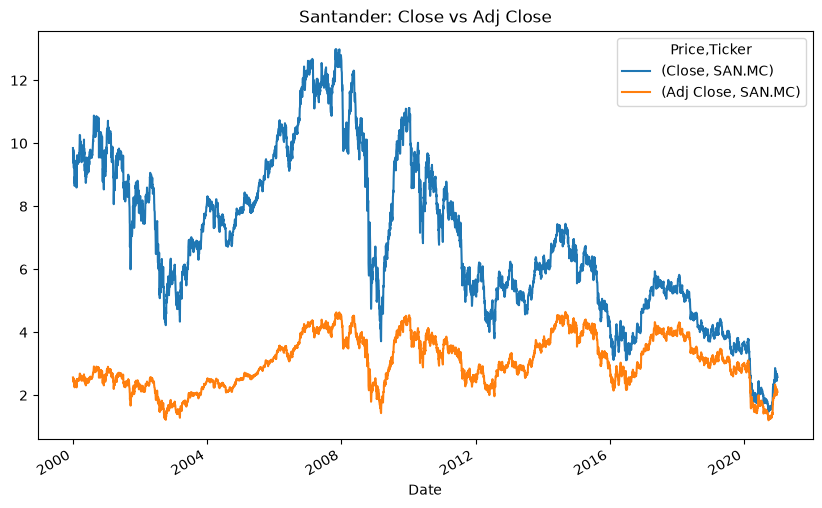

In [4]:
# Hacemos un gráfico con los precios de cierre y ajustado
san_OHLC_df[['Close', 'Adj Close']].plot(figsize=(10, 6))
plt.title('Santander: Close vs Adj Close');

También podemos bajarnos la información sobre dividendos y splits de Yahoo Finance.

In [5]:
# Crear un objeto para el símbolo de Banco Santander
symbol = "SAN.MC"  # SAN.MC es el símbolo de Banco Santander en el mercado continuo español

# Descargar los datos de dividendos
san_data = yf.Ticker(symbol)
san_div = san_data.dividends[start_date:end_date]

# Descargar los datos de splits
san_split = san_data.splits[start_date:end_date]

print("\nFechas de Splits:")
print(san_split)

print("\n")

print("Fechas de Dividendos:")
print(san_div)




Fechas de Splits:
Date
2011-01-17 09:00:00+01:00    1.015385
2020-11-16 09:00:00+01:00    1.043478
Name: Stock Splits, dtype: float64


Fechas de Dividendos:
Date
2000-01-31 09:00:00+01:00    0.047603
2000-05-02 09:00:00+02:00    0.050087
2000-05-04 09:00:00+02:00    0.054094
2000-07-31 09:00:00+02:00    0.057925
2000-08-02 09:00:00+02:00    0.057219
                               ...   
2018-07-30 09:00:00+02:00    0.062292
2018-10-18 09:00:00+02:00    0.033542
2019-01-30 09:00:00+01:00    0.062292
2019-04-29 09:00:00+02:00    0.062292
2019-10-30 09:00:00+01:00    0.095833
Name: Dividends, Length: 84, dtype: float64


Ahora nos bajamos datos de algunos de los indices bursatiles mas importantes del mundo.

In [6]:
# Definimos un diccionarios con los índices que vamos a utilizar
indices_dic = {'sp500': '^GSPC', #EEUU S&P 500
               'dax': '^GDAXI', #Alemania DAX 30
               'ftse': '^FTSE', #Londres FTSE 100
               'ibex': '^IBEX'} #España IBEX 35

In [7]:
# si quiero buscar los datos del sp500 y no me sé el ticker
indices_dic['sp500']

'^GSPC'

In [8]:
#si quiero bajarme todos los datos de los índices
list(indices_dic.values())

['^GSPC', '^GDAXI', '^FTSE', '^IBEX']

In [9]:
#nos bajamos los datos de Yahoo Finance
precios_OHLC = yf.download(list(indices_dic.values()), start=start_date, end=end_date, auto_adjust=False)


[*********************100%***********************]  4 of 4 completed


Vemos qué forma tienen los datos bajados

In [10]:
precios_OHLC.head(2)

Price         Adj Close                                       Close  \
Ticker            ^FTSE       ^GDAXI       ^GSPC ^IBEX        ^FTSE   
Date                                                                  
1990-01-02  2434.100098  1788.890015  359.690002   NaN  2434.100098   
1990-01-03  2463.699951  1867.290039  358.760010   NaN  2463.699951   

Price                                             High               ...  \
Ticker           ^GDAXI       ^GSPC ^IBEX        ^FTSE       ^GDAXI  ...   
Date                                                                 ...   
1990-01-02  1788.890015  359.690002   NaN  2443.300049  1788.890015  ...   
1990-01-03  1867.290039  358.760010   NaN  2466.199951  1867.290039  ...   

Price              Low               Open                                 \
Ticker           ^GSPC ^IBEX        ^FTSE       ^GDAXI       ^GSPC ^IBEX   
Date                                                                       
1990-01-02  351.980011   NaN  2425.500000  1788.890015  353.399994   NaN   
1990-01-03  357.890015   NaN  2445.800049  1867.290039  359.690002   NaN   

Price      Volume                            
Ticker      ^FTSE ^GDAXI        ^GSPC ^IBEX  
Date                                         
1990-01-02    0.0    0.0  162070000.0   NaN  
1990-01-03    0.0    0.0  192330000.0   NaN  

[2 rows x 24 columns]

In [11]:
precios_OHLC.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8006 entries, 1990-01-02 to 2020-12-30
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   (Adj Close, ^FTSE)   7831 non-null   float64
 1   (Adj Close, ^GDAXI)  7833 non-null   float64
 2   (Adj Close, ^GSPC)   7811 non-null   float64
 3   (Adj Close, ^IBEX)   6948 non-null   float64
 4   (Close, ^FTSE)       7831 non-null   float64
 5   (Close, ^GDAXI)      7833 non-null   float64
 6   (Close, ^GSPC)       7811 non-null   float64
 7   (Close, ^IBEX)       6948 non-null   float64
 8   (High, ^FTSE)        7831 non-null   float64
 9   (High, ^GDAXI)       7833 non-null   float64
 10  (High, ^GSPC)        7811 non-null   float64
 11  (High, ^IBEX)        6948 non-null   float64
 12  (Low, ^FTSE)         7831 non-null   float64
 13  (Low, ^GDAXI)        7833 non-null   float64
 14  (Low, ^GSPC)         7811 non-null   float64
 15  (Low, ^IBEX)         6948 non-n

In [12]:
precios_OHLC.isna().sum()

Price      Ticker
Adj Close  ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
Close      ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
High       ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
Low        ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
Open       ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
Volume     ^FTSE      175
           ^GDAXI     173
           ^GSPC      195
           ^IBEX     1058
dtype: int64

Veo cómo se puede accerder a los datos

In [13]:
precios_OHLC['Close'].head(2)

Ticker,^FTSE,^GDAXI,^GSPC,^IBEX
Date,,,,
1990-01-02,2434.100098,1788.890015,359.690002,NaN
1990-01-03,2463.699951,1867.290039,358.760010,NaN


Genero un dataframe con los valores OHLC del sp500

In [14]:
#defino el ticker que voy a utilizar
ticker = indices_dic['sp500']

In [15]:

#genero el dataframe usando un diccionario
sp500_OHLC = pd.DataFrame({
    'Open': precios_OHLC['Open'][ticker],
    'High': precios_OHLC['High'][ticker],
    'Low': precios_OHLC['Low'][ticker],
    'Close': precios_OHLC['Close'][ticker],
    'Adj Close': precios_OHLC['Adj Close'][ticker],
    'Volume': precios_OHLC['Volume'][ticker]
})

sp500_OHLC.head(2)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1990-01-02,353.399994,359.690002,351.980011,359.690002,359.690002,162070000.0
1990-01-03,359.690002,360.589996,357.890015,358.760010,358.760010,192330000.0


Vamos a realizar una gráfica de velas con los precios del sp500 del año 2018

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight

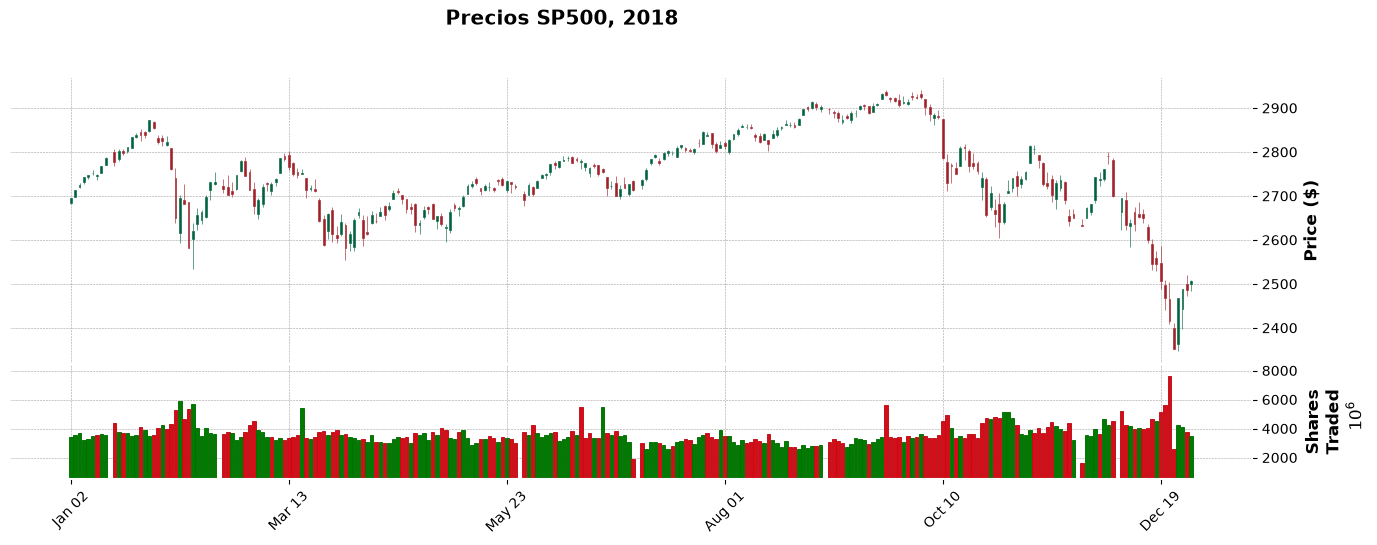

In [16]:
mpf.plot(
            sp500_OHLC.loc['2018'], #seleccionamos los datos de 2018
            type='candle', #tipo de gráfico
            style='charles', #estilo del gráfico
            title='Precios SP500, 2018',
            ylabel='Price ($)',
            volume=True, #añade el gráfico de volumen
            ylabel_lower='Shares\nTraded',
            figratio=(30, 10), #tamaño del gráfico
            )

EJERCICIO: Crea una gráfica de velas con los datos del mes de julio del año 2018 del índice sp500

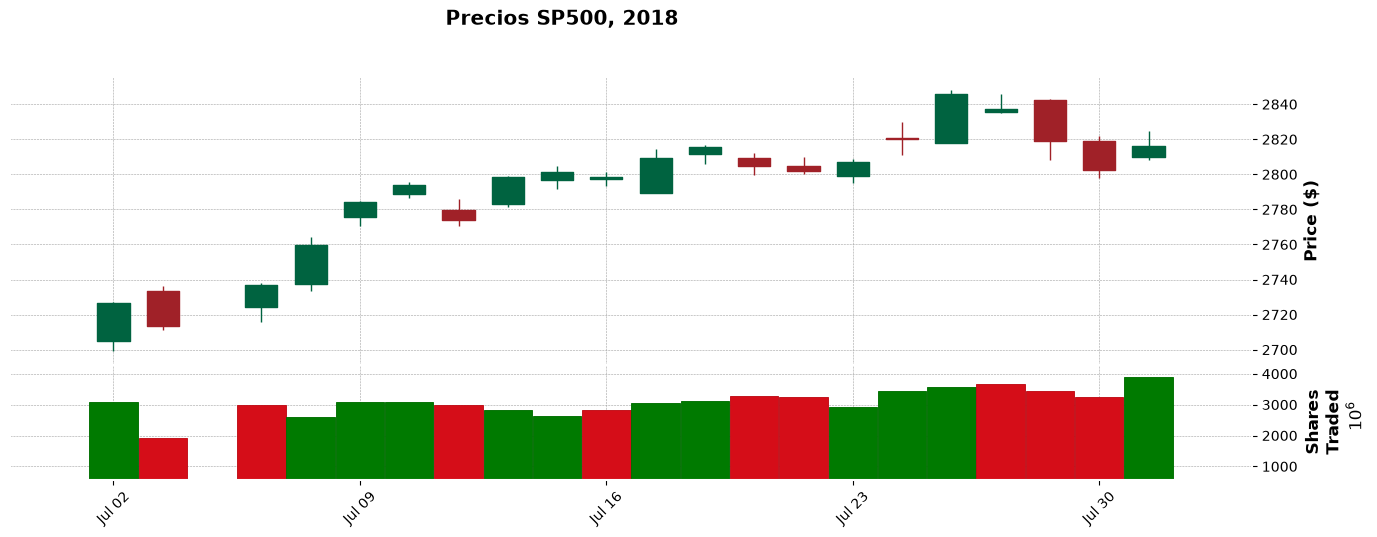

In [17]:
mpf.plot(
  sp500_OHLC.loc['2018-07'], #seleccionamos los datos de 2018
  type='candle', #tipo de gráfico
  style='charles', #estilo del gráfico
  title='Precios SP500, 2018',
  ylabel='Price ($)',
  volume=True, #añade el gráfico de volumen
  ylabel_lower='Shares\nTraded',
  figratio=(30, 10), #tamaño del gráfico
  )

Ejercicio: Crear una grafica con los datos de enero de 2025 de sp500 y otro gráfico del dax

In [18]:
start_date = '1990-01-01'
end_date = '2025-11-20'

In [19]:
precios_OHLC = yf.download(list(indices_dic.values()), start=start_date, end=end_date, auto_adjust=False)

[*********************100%***********************]  4 of 4 completed


In [20]:
#defino el ticker que voy a utilizar
ticker = indices_dic['sp500']
#genero el dataframe usando un diccionario
sp500_OHLC = pd.DataFrame({
    'Open': precios_OHLC['Open'][ticker],
    'High': precios_OHLC['High'][ticker],
    'Low': precios_OHLC['Low'][ticker],
    'Close': precios_OHLC['Close'][ticker],
    'Adj Close': precios_OHLC['Adj Close'][ticker],
    'Volume': precios_OHLC['Volume'][ticker]
})

sp500_OHLC.head(2)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1990-01-02,353.399994,359.690002,351.980011,359.690002,359.690002,162070000.0
1990-01-03,359.690002,360.589996,357.890015,358.760010,358.760010,192330000.0


In [21]:
sp500_OHLC

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1990-01-02,353.399994,359.690002,351.980011,359.690002,359.690002,1.620700e+08
1990-01-03,359.690002,360.589996,357.890015,358.760010,358.760010,1.923300e+08
1990-01-04,358.760010,358.760010,352.890015,355.670013,355.670013,1.770000e+08
1990-01-05,355.670013,355.670013,351.350006,352.200012,352.200012,1.585300e+08
1990-01-08,352.200012,354.239990,350.540009,353.790009,353.790009,1.401100e+08
...,...,...,...,...,...,...
2025-11-13,6826.470215,6828.049805,6724.720215,6737.490234,6737.490234,5.473720e+09
2025-11-14,6672.140137,6774.310059,6646.870117,6734.109863,6734.109863,5.042660e+09
2025-11-17,6713.609863,6754.500000,6638.899902,6672.410156,6672.410156,5.204220e+09


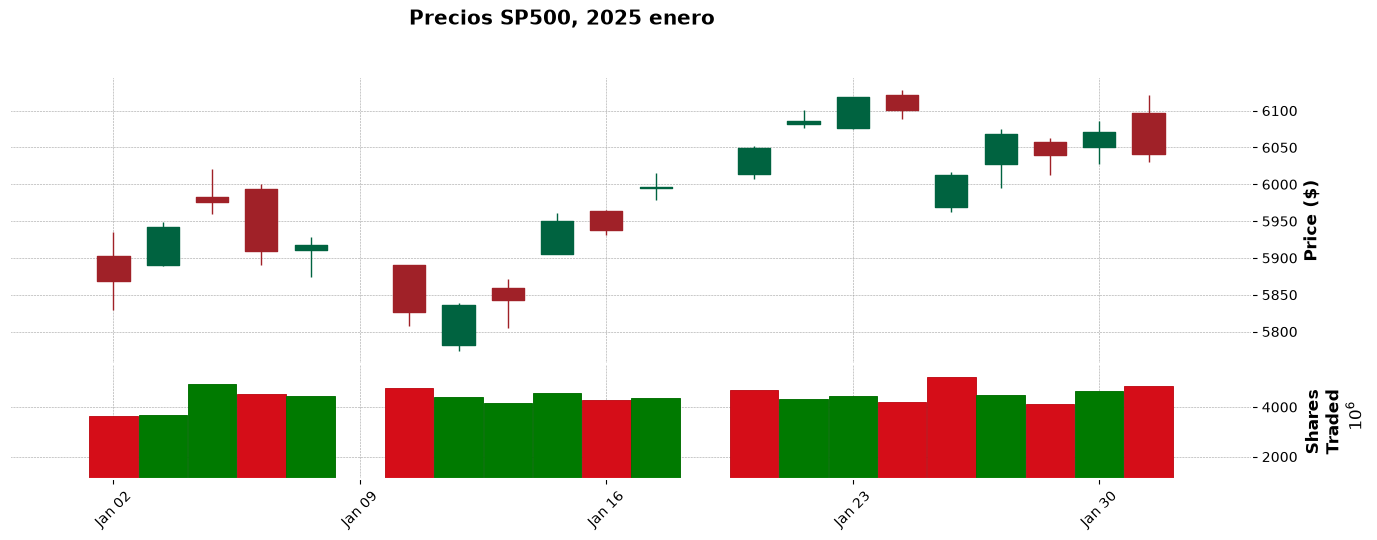

In [22]:
mpf.plot(
  sp500_OHLC.loc['2025-01'], #seleccionamos los datos de 2018
  type='candle', #tipo de gráfico
  style='charles', #estilo del gráfico
  title='Precios SP500, 2025 enero',
  ylabel='Price ($)',
  volume=True, #añade el gráfico de volumen
  ylabel_lower='Shares\nTraded',
  figratio=(30, 10), #tamaño del gráfico
  )

In [23]:
#defino el ticker que voy a utilizar
ticker = indices_dic['dax']
#genero el dataframe usando un diccionario
dax_OHLC = pd.DataFrame({
    'Open': precios_OHLC['Open'][ticker],
    'High': precios_OHLC['High'][ticker],
    'Low': precios_OHLC['Low'][ticker],
    'Close': precios_OHLC['Close'][ticker],
    'Adj Close': precios_OHLC['Adj Close'][ticker],
    'Volume': precios_OHLC['Volume'][ticker]
})

dax_OHLC

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1990-01-02,1788.890015,1788.890015,1788.890015,1788.890015,1788.890015,0.0
1990-01-03,1867.290039,1867.290039,1867.290039,1867.290039,1867.290039,0.0
1990-01-04,1830.920044,1830.920044,1830.920044,1830.920044,1830.920044,0.0
1990-01-05,1812.900024,1812.900024,1812.900024,1812.900024,1812.900024,0.0
1990-01-08,1841.469971,1841.469971,1841.469971,1841.469971,1841.469971,0.0
...,...,...,...,...,...,...
2025-11-13,24367.699219,24416.330078,24027.919922,24041.619141,24041.619141,60792900.0
2025-11-14,23977.720703,23992.119141,23609.060547,23876.550781,23876.550781,64036000.0
2025-11-17,23890.480469,23928.480469,23529.730469,23590.519531,23590.519531,46448300.0


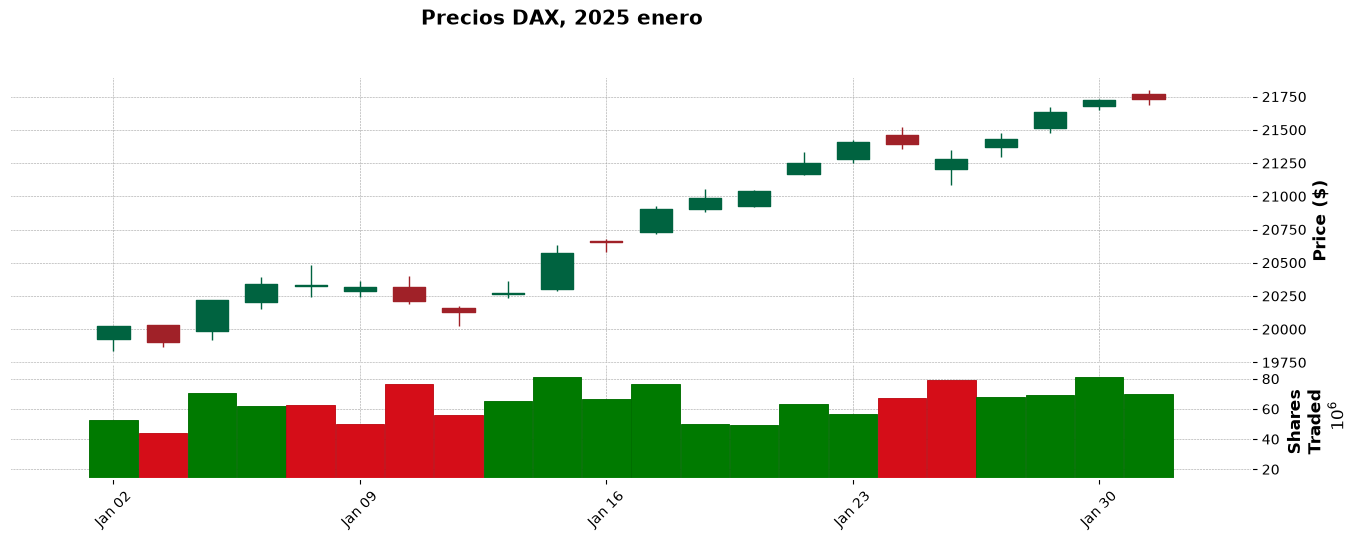

In [24]:

mpf.plot(
  dax_OHLC.loc['2025-01'], #seleccionamos los datos de 2018
  type='candle', #tipo de gráfico
  style='charles', #estilo del gráfico
  title='Precios DAX, 2025 enero',
  ylabel='Price ($)',
  volume=True, #añade el gráfico de volumen
  ylabel_lower='Shares\nTraded',
  figratio=(30, 10), #tamaño del gráfico
  )

## ANÁLISIS Y TRATAMIENTO INICIAL

A PARTIR DE AHORA VAMOS A TRABAJAR CON LOS PRECIOS DE CIERRE AJUSTADOS

Genero un dataframe con los valores de cierre de los índices

In [25]:
# me quedo con los datos de cierre ajustados
precios_df = precios_OHLC['Close']

#cambio los nombres a las columnas
precios_df.columns = list(indices_dic.keys())

precios_df.head(2)

,sp500,dax,ftse,ibex
Date,,,,
1990-01-02,2434.100098,1788.890015,359.690002,NaN
1990-01-03,2463.699951,1867.290039,358.760010,NaN



Hago un gráfico inicial

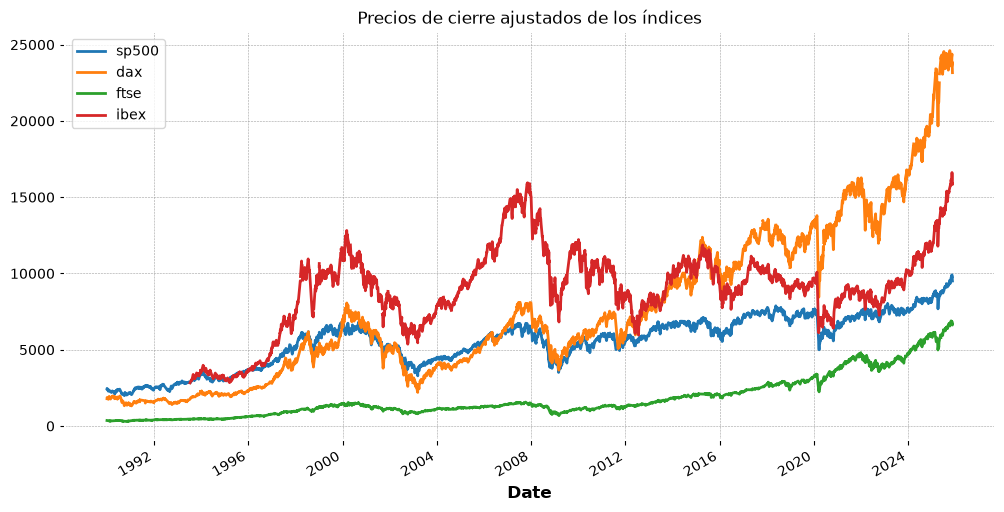

In [26]:
precios_df.plot(figsize=(12,6));
plt.title('Precios de cierre ajustados de los índices');

Veo que algunos indices tiene valores durante un periodo de tiempo más amplio que otros. Voy a quedarme con el periodo de tiempo que tienen todos los índices

In [27]:
precios_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 9270 entries, 1990-01-02 to 2025-11-19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sp500   9065 non-null   float64
 1   dax     9081 non-null   float64
 2   ftse    9039 non-null   float64
 3   ibex    8200 non-null   float64
dtypes: float64(4)
memory usage: 362.1 KB


Eliminamos los NANs:
* Primero eliminamos las filas con todos los valores a Nan
* Luego eliminamos las filas con algún valor a Nan

In [28]:
# Filas con todos los valores a NaN
precios_df.dropna(how='all' ,inplace=True)
precios_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 9270 entries, 1990-01-02 to 2025-11-19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sp500   9065 non-null   float64
 1   dax     9081 non-null   float64
 2   ftse    9039 non-null   float64
 3   ibex    8200 non-null   float64
dtypes: float64(4)
memory usage: 362.1 KB


In [29]:
# Filas con al menos un valor a NaN
precios_df.dropna(how='any' ,inplace=True)
precios_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 7838 entries, 1993-07-12 to 2025-11-19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sp500   7838 non-null   float64
 1   dax     7838 non-null   float64
 2   ftse    7838 non-null   float64
 3   ibex    7838 non-null   float64
dtypes: float64(4)
memory usage: 306.2 KB


VUELVO A HACER LA GRÁFICA CON LOS PRECIOS

In [30]:
precios_df.iloc[0,:]

sp500    2830.899902
dax      1808.739990
ftse      448.980011
ibex     2826.399902
Name: 1993-07-12 00:00:00, dtype: float64

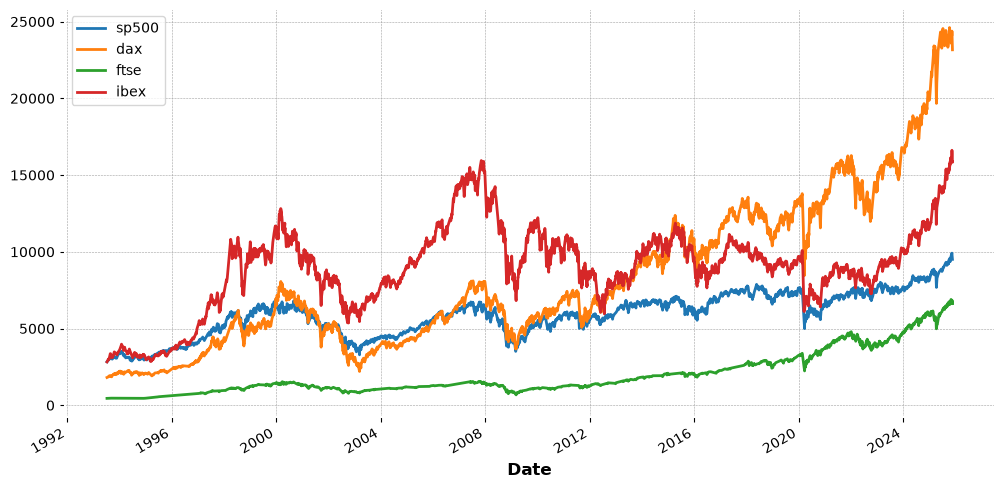

In [31]:
precios_df.plot(figsize=(12,6));

Para poder comparar los índices, normalizamos los datos

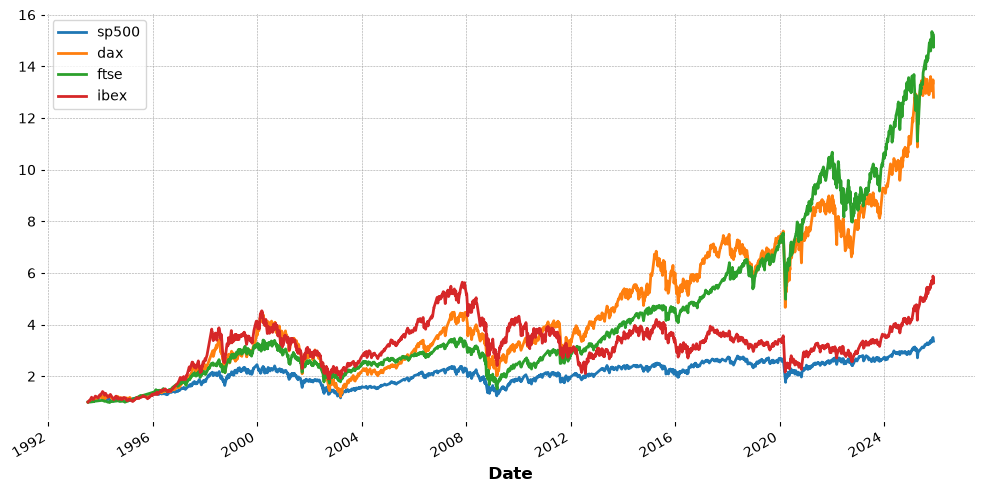

In [32]:
# Dividimos los precios por el primer valor, de forma que todos los precios empiecen en 1
precios_unif_df = precios_df / precios_df.iloc[0]

precios_unif_df.plot(figsize=(12,6));

Veamos ahora qué ocurre si tenemos dos fuentes de datos distintas, tendremos que mezclar y normalizar los datos

Leemos los datos del Ibex desde ficheros csv

In [39]:
import pandas as pd
# cargamos los datos

# para ejecutar en local
ibex = pd.read_csv('./ibex.csv', index_col=0, parse_dates=True).close
ibex_div = pd.read_csv('./ibex_div.csv', index_col=0, parse_dates=True).close

# para ejecutar en colab
data_ibex = pd.concat([ibex, ibex_div], axis=1).dropna()
data_ibex.columns = ['ibex', 'ibex_div']

Hacemos unas gráficas iniciales

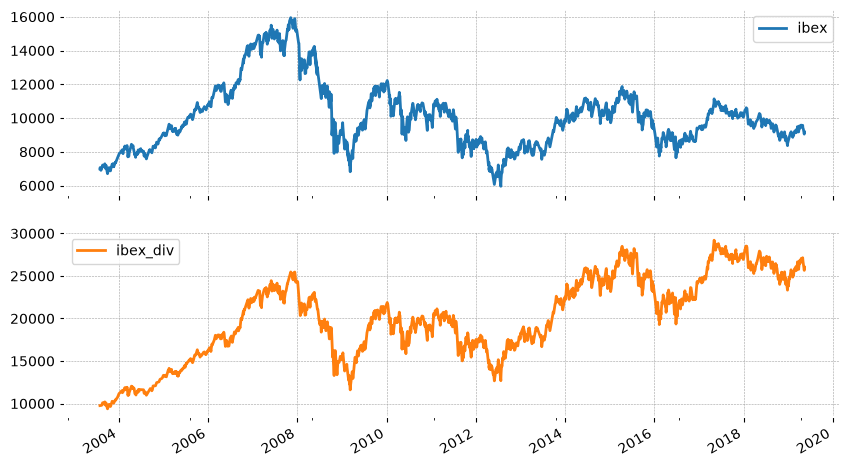

In [40]:
data_ibex.plot(subplots=True, figsize=(10, 6));

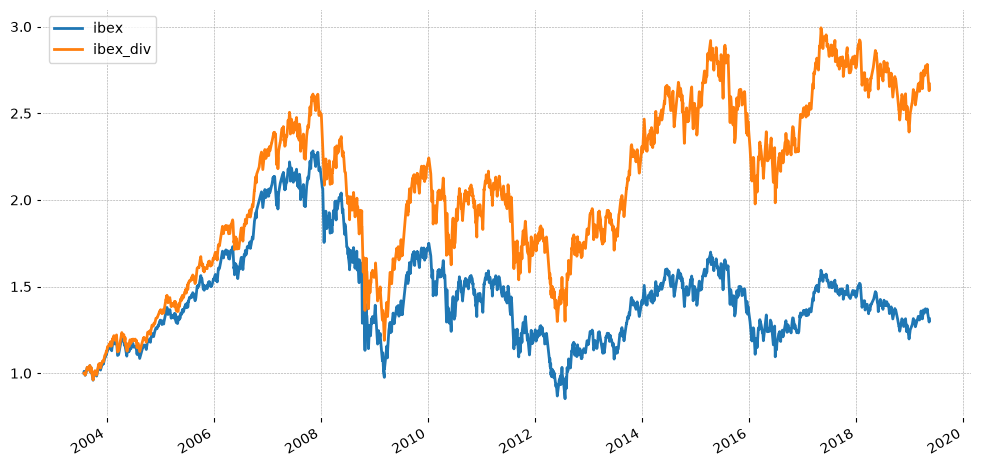

In [41]:
#unificamos los datos para poder comparar
ibex_unif = data_ibex/data_ibex.iloc[0]

ibex_unif.plot(figsize=(12, 6));

OJO: Los datos del Ibex y del resto de índices no corresponden a las mismas fechas, por lo que tenemos que hacer un merge de los datos

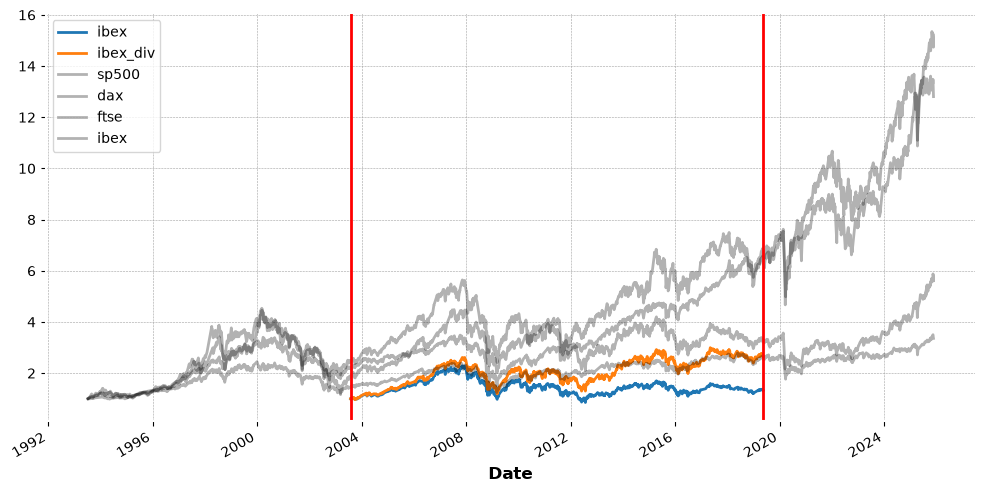

In [42]:
fig, ax = plt.subplots(figsize=(12, 6))
ibex_unif.plot(ax=ax)
precios_unif_df.plot(ax=ax, color='k', alpha=0.3);
plt.axvline(x=ibex_unif.index[0],color='r')
plt.axvline(x=ibex_unif.index[-1],color='r');


C:\Users\sulli\AppData\Local\Temp\ipykernel_7228\2169001142.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  ind_fin_df = pd.concat([data_ibex['ibex_div'], precios_df], axis=1).dropna()


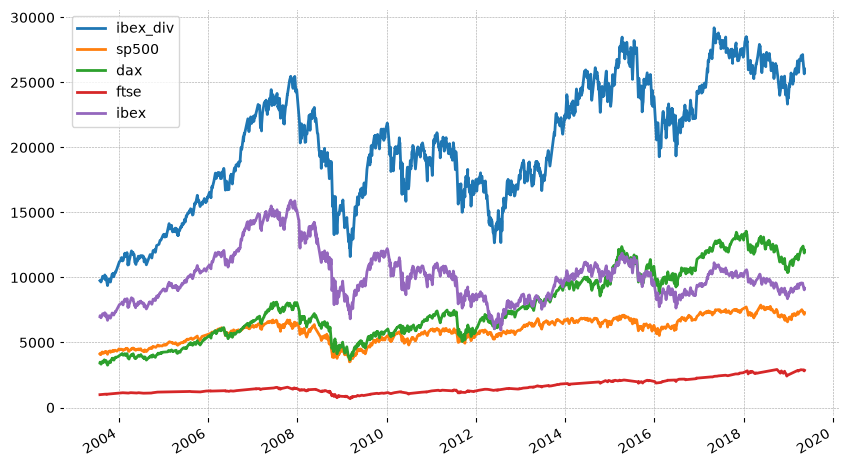

In [43]:
#juntamos los dos dataframes en uno solo pero nos aseguramos de que las fechas sean las mismas
ind_fin_df = pd.concat([data_ibex['ibex_div'], precios_df], axis=1).dropna()

#hacemos un gráfico con los índices
ind_fin_df.plot(figsize=(10, 6));


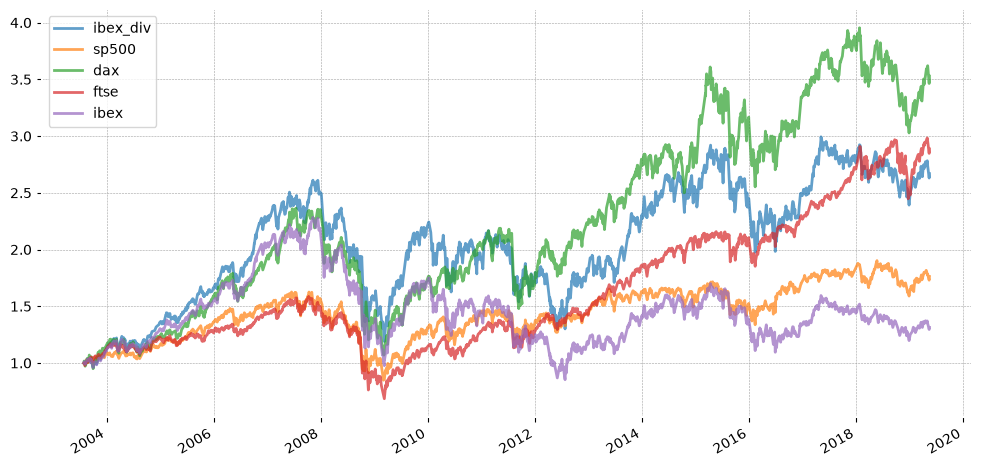

In [44]:
# normalizamos los precios
ind_fin_unif_df = ind_fin_df / ind_fin_df.iloc[0]

#hacemos un gráfico con los índices normalizados
ind_fin_unif_df.plot(figsize=(12,6), alpha=0.7);

CUIDADO: AL comparar índices, tenemos que tener claro si incluyen o no dividendos. En este caso, el índice del Ibex no incluye dividendos.

## CÁLCULO DE RENTABILIDADES LOGARITMICAS

La teoría financiera siempre ha caracterizado por:

Los inversores tienen **aversión al riesgo**

Los activos los representamos por el **binomio rentabilidad-riesgo**:

La **rentabilidad** se mide como la media de los rentornos

El **riesgo** se mide a través de la volatilidad, que es la desviación estándar de los rendimientos.

Vamos a verlo con algunos datos reales.

### Primero calculamos los retornos

# Rendimiento Aritmético

* **Qué es:** Es el cambio porcentual simple de un activo entre dos puntos en el tiempo. Se calcula directamente con los precios de inicio ($P_i$) y final ($P_f$).
* **Fórmula:**
    $$R_{aritmético} = \frac{P_f}{P_i} - 1$$
* **Ejemplo:** Si una acción pasa de $200$  a  $100$, el rendimiento aritmético es:

    $$\left( \frac{100}{200} - 1 \right) = -0.5 \text{ o } -50\%$$
* **Uso:** Es el más fácil de entender e intuitivo para el público general.

# Rendimiento Logarítmico

* **Qué es:** Es el cambio porcentual medido de forma continua a lo largo de un período, a menudo utilizado en análisis financiero y econométrico.
* **Fórmula:**
    $$R_{logarítmico} = \ln\left(\frac{P_f}{P_i}\right)$$
* **Ejemplo:** Con los mismos precios de $200$  a  $100$, el rendimiento logarítmico es:

    $$\ln\left(\frac{100}{200}\right) \approx -0.693 \text{ o } -69.3\%$$
* **Uso:** Es preferido en finanzas por ser aditivo en el tiempo y más adecuado para la modelización estadística.

# Diferencias clave

| Característica | Rendimiento Aritmético | Rendimiento Logarítmico |
| :--- | :--- | :--- |
| **Aditividad en el tiempo** | No es aditivo; requiere multiplicar los factores de retorno. | Es aditivo; los rendimientos de varios períodos se suman directamente. |
| **Comportamiento para grandes variaciones** | La diferencia entre el rendimiento aritmético y el logarítmico se vuelve significativa a medida que las variaciones porcentuales son mayores. | Es menos intuitivo pero más útil para análisis estadístico. |
| **Distribución** | No asume que los rendimientos siguen una distribución normal. | Se aproxima a una distribución normal si los precios siguen una distribución log-normal, lo que facilita el análisis. |

Los rendimiento aritméticos siguen una distribución lognormal. **Los rendimientos logarítmicos siguen una distribución normal**.

Ambos rendimientos son equivalentes cuando los rendimientos son pequeños. Veamos como se comportan los rendimientos aritméticos y logarítmicos para distintos valores de rendimiento:

$$ P_f = P_i (1+R_{aritmetico}) $$

Entonces si lo desarrollamos:

$$R_{logarítmico} = \ln\left(\frac{P_f}{P_i}\right) = \ln\left(\frac{P_i (1+R_{aritmetico})}{P_i}\right) = \ln\left(1+R_{aritmetico}\right)$$

### Aproximación matemática (Serie de Taylor)

Para entender por qué son similares cuando el rendimiento es bajo, utilizamos la expansión en serie de Taylor de la función $\ln(1+x)$ alrededor de 0:

$$\ln(1+x) \approx x - \frac{x^2}{2} + \frac{x^3}{3} - \dots$$

Si $R_{aritmetico}$ es un valor pequeño (cercano a 0), los términos elevados al cuadrado o al cubo son insignificantes. Por lo tanto, podemos aproximar:

$$R_{logarítmico} \approx R_{aritmético}$$

> **Nota:** Esta aproximación falla cuando la volatilidad es alta.

### Comparación numérica de la divergencia

A medida que la magnitud del rendimiento aumenta, la diferencia entre ambos métodos se vuelve crítica:

| Rendimiento Aritmético ($R_a$) | Factor ($1+R_a$) | Rendimiento Logarítmico ($\ln(1+R_a)$) | Diferencia |
| :--- | :--- | :--- | :--- |
| **+1%** | 1.01 | **0.995%** | ~0.005% (Insignificante) |
| **+10%** | 1.10 | **9.53%** | ~0.47% |
| **+20%** | 1.20 | **18.23%** | ~1.77% |
| **+50%** | 1.50 | **40.55%** | ~9.45% (Significativa) |
| **+100%** | 2.00 | **69.31%** | ~30.7% (Muy grande) |
| **-50%** | 0.50 | **-69.31%** | Asimetría notable |

### Conclusión sobre las Distribuciones

Esta relación matemática explica por qué se prefieren los rendimientos logarítmicos en modelización:

1.  **Límite de los Precios:** Los precios ($P_t$) no pueden ser negativos (mínimo 0). Esto implica que el rendimiento aritmético mínimo es $-100\%$. Esta asimetría hace que los precios sigan una distribución **Log-normal**.
2.  **Normalidad:** Al transformar esos precios mediante logaritmos, los rendimientos resultantes ($R_{log}$) pueden extenderse de $-\infty$ a $+\infty$. Esto permite asumir una distribución **Normal** (Gaussiana), lo cual es un requisito indispensable para la mayoría de los modelos de riesgo (como *VaR*) y valoración de opciones (como *Black-Scholes*).

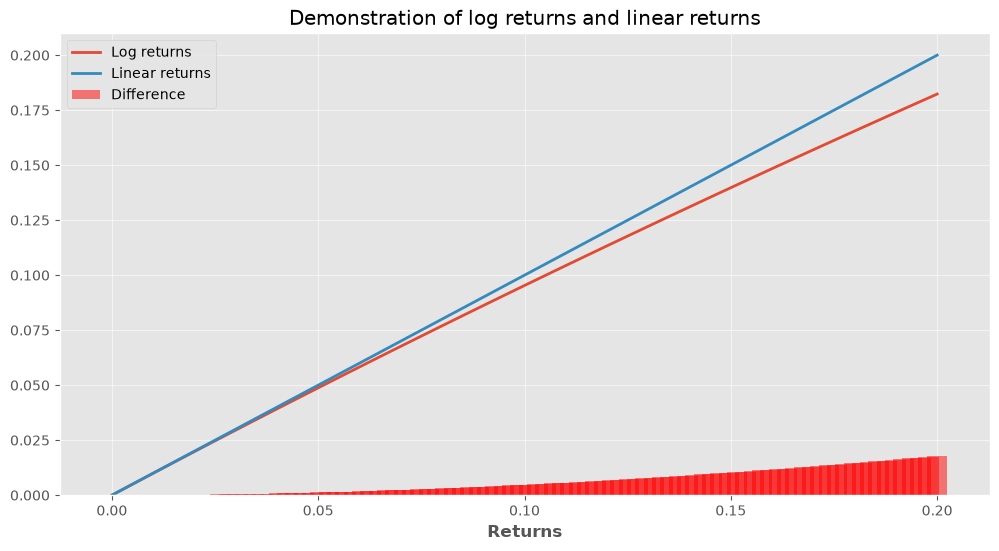

In [45]:
plt.style.use('ggplot')
x_returns = np.linspace(0.0001, 0.2, 100) # Generate 100 numbers between 0.0001 and 0.2
y_returns = np.log(1 + x_returns) # Calculate the logarithmic returns from the linear returns

# Plot the linear and log returns
fig, ax = plt.subplots(figsize=(12, 6))
plt.plot(x_returns, y_returns, label='Log returns') # Plot the log returns
plt.plot(x_returns, x_returns, label='Linear returns') # Plot the linear returns
plt.bar(x_returns, x_returns-y_returns, width=0.005, color='r', alpha=0.5, label='Difference', ) # Plot the difference between the two returns
plt.legend()
plt.xlabel('Returns')
plt.title('Demonstration of log returns and linear returns');

___

## Ejercicio
1.- Recupera el valor del retorno aritmetico a partir del logaritmico, genera una funcion que lo haga.

___

A partir de ahora vamos a trabajar con retornos logarítmico.

VAMOS A CALCULAR RETORNOS DIARIOS, MENSUALES Y ANUALES

Calcula el retorno diario de un dataframe con los precios diarios

Calcular los retornos mensuales de un dataframe con los precios diarios

HACEMOS UN GRÁFICO DE BARRAS DE LOS RETORNOS ANUALES